In [1]:
import akshare as ak
import backtrader as bt
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
class DualMAStrategy(bt.Strategy):
    # 注意类名拼写：Strategy 不是 Startegy，不影响运行但建议改
    params = (("fast", 5), ("slow", 20))

    def __init__(self):
        self.fast_ma = bt.indicators.SMA(period=self.p.fast)
        self.slow_ma = bt.indicators.SMA(period=self.p.slow)

    def next(self):
        if not self.position:
            if self.fast_ma[0] > self.slow_ma[0]:
                self.buy()
        elif self.fast_ma[0] < self.slow_ma[0]:
            self.close()


In [39]:
def test_single(symbol="sz000001", 
         start_date="20240101",
         end_date="20241125", 
         Sizers = "percent",
         strategy=DualMAStrategy,
         stake=100,
         origin_cash = 50000,
         plot = False,
         fast = 5,
         slow = 20,
         percent = 95
         ):
    """
    Args:
        symbol: 腾讯源股票代码，如 "sz000001"。
        start_date: 开始日期，格式 YYYYMMDD。
        end_date: 结束日期，格式 YYYYMMDD。
        Sizers: 加仓方式
        strategy: bt.Strategy 子类。
        stake: 每次买入股数，最低 100。
        origin_cash: 起始资金。
        plot: 是否展示k线图
        slow: 策略中的slow参数
        fast: 策略中的fast参数
        percent: 仓位百分比
    Returns:
        None，结果直接打印并绘图。
    """
    print(f"=============== {symbol}: {start_date} --- {end_date} ===============")

    df = ak.stock_zh_a_hist_tx(
        symbol=symbol, start_date=start_date,
        end_date=end_date, adjust="qfq"
    )

    df = df.rename(columns={"amount": "volume"})
    df["date"] = pd.to_datetime(df["date"])
    df.set_index("date", inplace=True)

    data = bt.feeds.PandasData(
        dataname=df[["open", "high", "low", "close", "volume"]]
    )

    cerebro = bt.Cerebro()
    cerebro.broker.setcommission(commission=0.0005)
    cerebro.broker.set_slippage_fixed(fixed=0.01)
    cerebro.adddata(data)
    cerebro.addstrategy(strategy, fast=fast, slow=slow)
    cerebro.broker.setcash(origin_cash)
    
    if Sizers == "fixed":
        cerebro.addsizer(bt.sizers.FixedSize, stake=stake)
    if Sizers == "percent":
        cerebro.addsizer(bt.sizers.PercentSizer, percents = percent)

    cerebro.addanalyzer(bt.analyzers.Returns, _name="returns")
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name="drawdown")
    cerebro.addanalyzer(
        bt.analyzers.SharpeRatio, 
        _name="sharpe",
        timeframe=bt.TimeFrame.Days,  # 告诉它数据是日线
        compression=1,                # 每天的频率
        riskfreerate=0.0,             # 无风险利率设为 0（新手回测通常设为0即可）
        annualize=True,               # 强制开启年化
        factor=252                    # 一年 252 个交易日，让引擎自己换算
    )
    
    # ✅ 新增：添加一个记录每日收益率的分析器
    cerebro.addanalyzer(bt.analyzers.TimeReturn, _name="timereturn")

    print(f"回测前资金: {cerebro.broker.getvalue():.2f}")
    results = cerebro.run()
    strat = results[0]

    final_value = cerebro.broker.getvalue()
    print(f"回测后资金: {final_value:.2f}")

    returns = strat.analyzers.returns.get_analysis()
    drawdown = strat.analyzers.drawdown.get_analysis()
    sharpe = strat.analyzers.sharpe.get_analysis()

    print(f"总收益率: {returns['rtot'] * 100:.2f}%")
    print(f"最大回撤: {drawdown['max']['drawdown']:.2f}%")
    print(f"夏普比率: {sharpe.get('sharperatio', 0)}")

    # ✅ 注释掉原来的K线图，我们改用外部画图
    if plot:
        cerebro.plot()  
    
    # ✅ 提取每日收益率，并转换成资金净值曲线
    # TimeReturn 返回的是每日的收益率（如 0.01 代表涨1%）
    time_return = strat.analyzers.timereturn.get_analysis()
    # 将收益率转为 Series，+1 后累乘，算出每天的净值（起点为1）
    nav_series = (pd.Series(time_return) + 1).cumprod()
    sharpe_val = sharpe.get('sharperatio', 0)
    # ✅ 返回这个净值数据，供主程序画图
    return {
        "nav": nav_series,           # 每日净值曲线
        "returns": returns['rtot'] * 100, # 总收益率
        "sharpe": sharpe_val         # 夏普比率
    }

In [4]:
def plot_result(results:dict):
    color = ['blue', 'green', 'red', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan', 'magenta', 'yellow', 'lime', 'navy', 'teal', 'coral', 'gold']  
    
    plt.figure(figsize=(12, 7))
    for index, (key, data_dict) in enumerate(results.items()):
        # ✅ 注意这里改成了 data_dict["nav"]
        nav_series = data_dict["nav"] 
        if nav_series is None or nav_series.empty:
            continue
        current_color = color[index % len(color)]
        plt.plot(nav_series.index, nav_series.values, label=key, color=current_color, linewidth=1.5)

    plt.title("Dual MA Strategy - Parameter Grid Search")
    plt.legend(loc="best")
    plt.grid(True, alpha=0.3)
    plt.show()

In [5]:
def test_single_symbol_with_different_params(
  fast = [5],
  slow = [20],
  symbol = "sz000001",
  start = "20240101",
  end = "20250101",
  plot = True    
):
    """
    args:
        fast: 快线天数
        slow: 慢线天数
        symbol: 选股
        start: 开始日期
        end: 结束日期
    """
    result = {}
    print(">>> 开始运行网格搜索参数回测...")
    for i in fast:
        for j in slow:
            if i >= j:
                continue 
            key_name = f'fast:{i}-slow:{j}'
            print(f"正在跑 {key_name}...")
            # result 现在接收到的是一个字典
            result[key_name] = test_single(symbol=symbol, fast=i, slow=j, start_date=start, end_date=end)
            
    color = ['blue', 'green', 'red', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan', 'magenta', 'yellow', 'lime', 'navy', 'teal', 'coral', 'gold']  

    if plot:
        plot_result(result)
    
    # ✅ 升级版业绩排名：把收益率和夏普比率一起打印出来
    print("\n=========== 最终业绩排名 (按收益率排序) ===========")
    print(f"{'参数组合':<20} | {'总收益率':<10} | {'夏普比率'}")
    print("-" * 50)
    
    # 排序时提取 data_dict["returns"]
    sorted_results = sorted(result.items(), key=lambda x: x[1]["returns"], reverse=True)
    
    for key, data_dict in sorted_results:
        ret = data_dict["returns"]
        shp = data_dict["sharpe"]
        # 格式化输出，保留两位小数
        print(f"{key:<20} | {ret:>7.2f}%   | {shp:>6.2f}")
    return

>>> 开始运行网格搜索参数回测...
正在跑 fast:3-slow:5...
=============== sz000001: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 65356.87
总收益率: 26.78%
最大回撤: 11.78%
夏普比率: 1.1909181719270612
正在跑 fast:3-slow:10...
=============== sz000001: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 57084.03
总收益率: 13.25%
最大回撤: 11.05%
夏普比率: 0.6504472626524619
正在跑 fast:3-slow:20...
=============== sz000001: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 47431.98
总收益率: -5.27%
最大回撤: 20.12%
夏普比率: -0.09979640009725528
正在跑 fast:10-slow:30...
=============== sz000001: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50926.14
总收益率: 1.84%
最大回撤: 13.46%
夏普比率: 0.19913354755280602


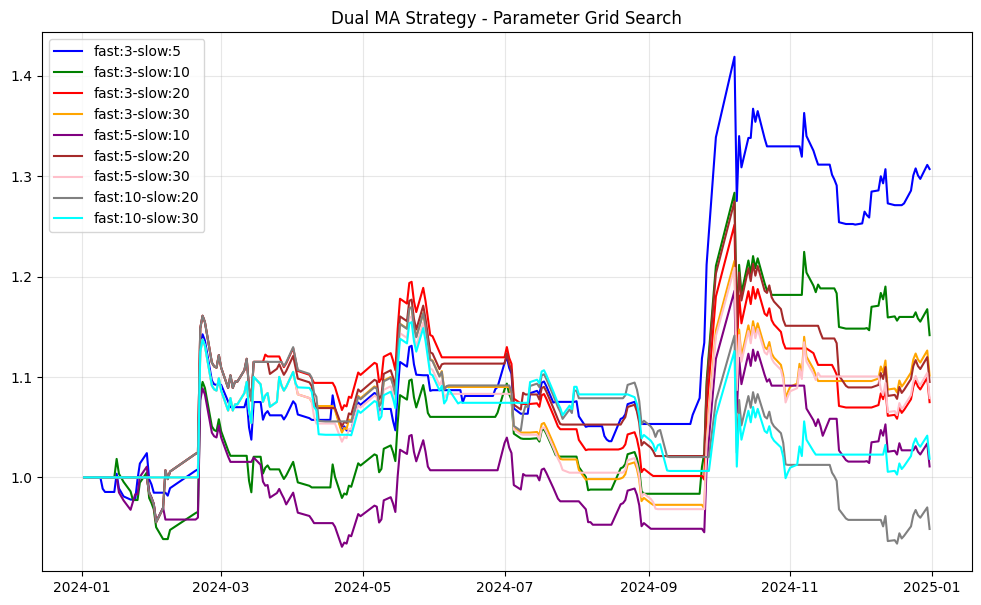


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:3-slow:5        |   26.78%   |   1.19
fast:3-slow:10       |   13.25%   |   0.65
fast:3-slow:30       |    9.66%   |   0.51
fast:5-slow:20       |    9.08%   |   0.49
fast:5-slow:30       |    7.61%   |   0.43
fast:3-slow:20       |    7.23%   |   0.42
fast:10-slow:30      |    1.84%   |   0.20
fast:5-slow:10       |    1.09%   |   0.17
fast:10-slow:20      |   -5.27%   |  -0.10


In [6]:
test_single_symbol_with_different_params(fast = [3,5,10], slow = [5,10,20,30], symbol='sz000001', start="20240101", end= "20250101")

>>> 开始运行网格搜索参数回测...
正在跑 fast:3-slow:5...
=============== sz000001: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 46895.23
总收益率: -6.41%
最大回撤: 11.66%
夏普比率: -0.4655333182388296
正在跑 fast:3-slow:10...
=============== sz000001: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 55398.37
总收益率: 10.25%
最大回撤: 8.62%
夏普比率: 0.9591774031666236
正在跑 fast:3-slow:20...
=============== sz000001: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 55895.26
总收益率: 11.15%
最大回撤: 7.45%
夏普比率: 1.0611329384622623
正在跑 fast:10-slow:30...
=============== sz000001: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 53310.42
总收益率: 6.41%
最大回撤: 9.17%
夏普比率: 0.6314803742561922


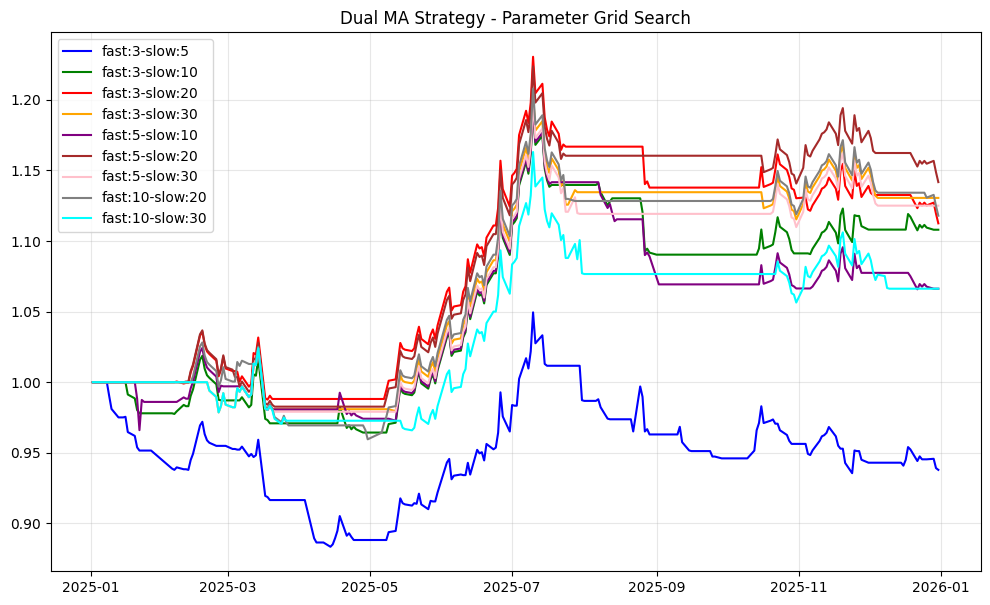


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:5-slow:20       |   13.25%   |   1.25
fast:3-slow:30       |   12.27%   |   1.17
fast:5-slow:30       |   11.78%   |   1.13
fast:10-slow:20      |   11.15%   |   1.06
fast:3-slow:20       |   10.66%   |   1.00
fast:3-slow:10       |   10.25%   |   0.96
fast:10-slow:30      |    6.41%   |   0.63
fast:5-slow:10       |    6.41%   |   0.60
fast:3-slow:5        |   -6.41%   |  -0.47


In [7]:
test_single_symbol_with_different_params(fast = [3,5,10], slow = [5,10,20,30], symbol='sz000001', start="20250101", end= "20260101")

>>> 开始运行网格搜索参数回测...
正在跑 fast:5-slow:20...
=============== sh510300: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 57358.18
总收益率: 13.73%
最大回撤: 7.91%
夏普比率: 1.348037810975367


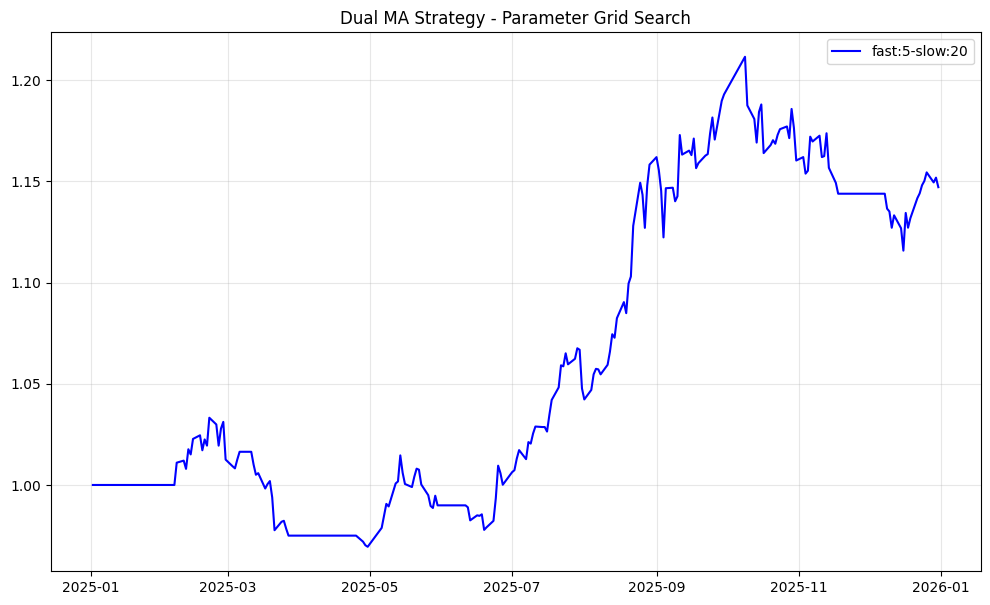


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:5-slow:20       |   13.73%   |   1.35


In [8]:
test_single_symbol_with_different_params(fast = [5], slow = [20], symbol='sh510300', start="20250101", end= "20260101")

>>> 开始运行网格搜索参数回测...
正在跑 fast:5-slow:20...
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50608.28
总收益率: 1.21%
最大回撤: 15.51%
夏普比率: 0.16116958091479866


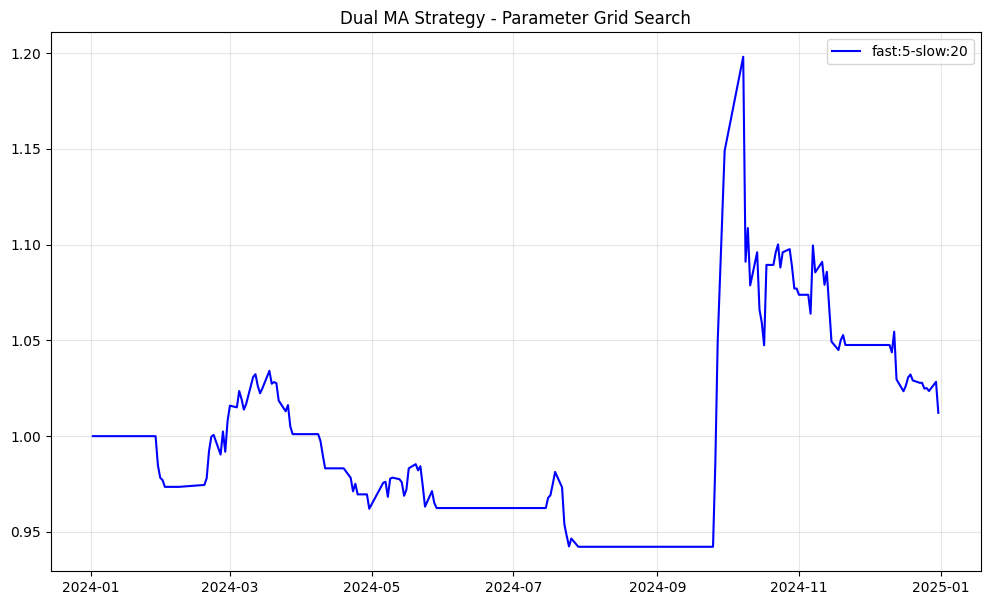


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:5-slow:20       |    1.21%   |   0.16


In [9]:
test_single_symbol_with_different_params(fast = [5], slow = [20], symbol='sh510300', start="20240101", end= "20250101")

>>> 开始运行网格搜索参数回测...
正在跑 fast:5-slow:20...
=============== sh518880: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 56857.84
总收益率: 12.85%
最大回撤: 7.62%
夏普比率: 1.2988091860792628


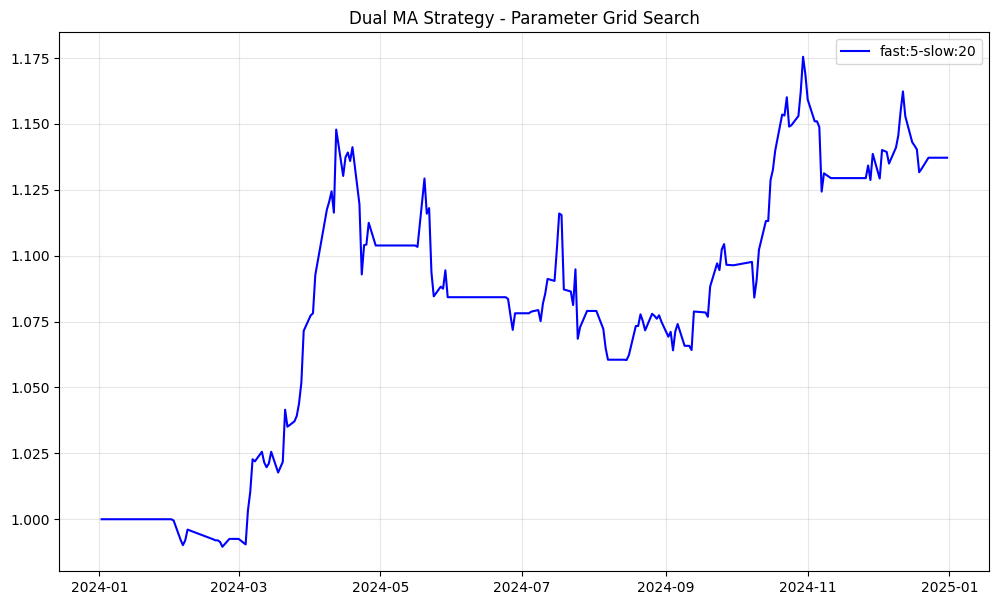


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:5-slow:20       |   12.85%   |   1.30
>>> 开始运行网格搜索参数回测...
正在跑 fast:5-slow:20...
=============== sh518880: 20250101 --- 20260101 ===============


  0%|          | 0/2 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 62240.56
总收益率: 21.90%
最大回撤: 12.28%
夏普比率: 1.463913207981605


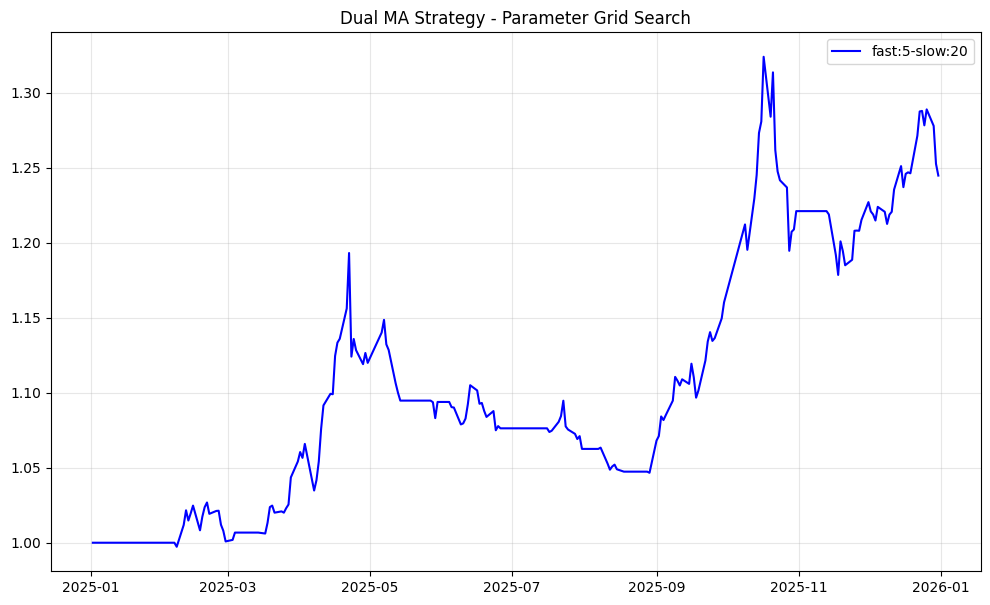


=========== 最终业绩排名 (按收益率排序) ===========
参数组合                 | 总收益率       | 夏普比率
--------------------------------------------------
fast:5-slow:20       |   21.90%   |   1.46


In [10]:
test_single_symbol_with_different_params(fast = [5], slow = [20], symbol='sh518880', start="20240101", end= "20250101")
test_single_symbol_with_different_params(fast = [5], slow = [20], symbol='sh518880', start="20250101", end= "20260101")

In [11]:
class DualMAStrategy_with_TrendMA(bt.Strategy):
    # 注意类名拼写：Strategy 不是 Startegy，不影响运行但建议改
    params = (("fast", 5), ("slow", 20), ("trend", 60))

    def __init__(self):
        self.fast_ma = bt.indicators.SMA(period=self.p.fast)
        self.slow_ma = bt.indicators.SMA(period=self.p.slow)
        self.trend_ma = bt.indicators.SMA(period = self.p.trend)
    def next(self):
        if not self.position:
            if self.fast_ma[0] > self.slow_ma[0] and self.data.close[0] > self.trend_ma[0]:
                self.buy()
        elif self.fast_ma[0] < self.slow_ma[0]:
            self.close()


=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 49915.15
总收益率: -0.17%
最大回撤: 15.51%
夏普比率: 0.08431803672639591
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50608.28
总收益率: 1.21%
最大回撤: 15.51%
夏普比率: 0.16116958091479866


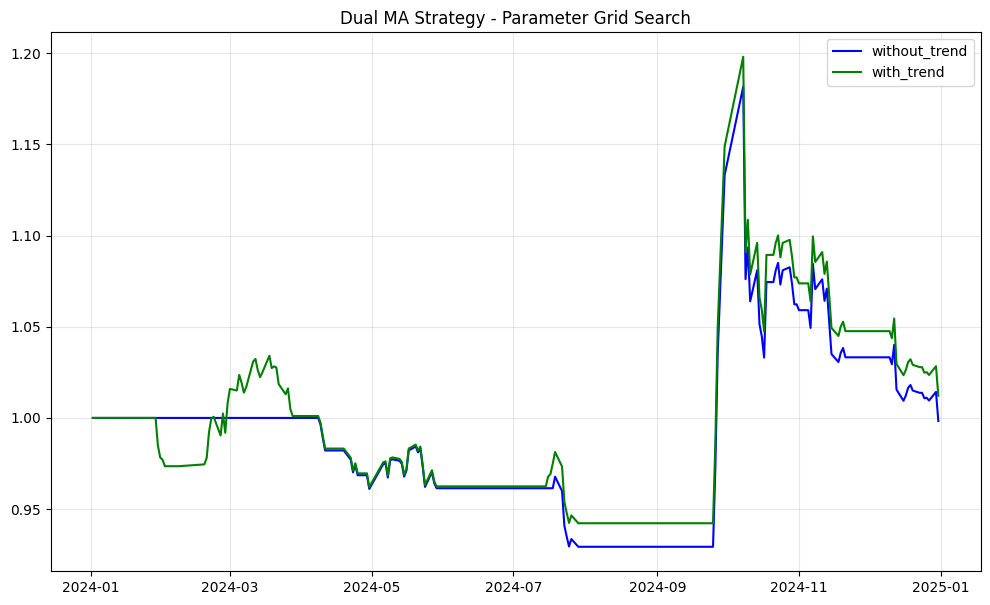

In [13]:
result = {}
result['without_trend']=test_single(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy_with_TrendMA)
result['with_trend']=test_single(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy)
plot_result(result)

In [14]:
class DualMAStrategy2(DualMAStrategy_with_TrendMA):
    def next(self):
        if not self.position:
            if self.fast_ma[0] > self.slow_ma[0] and self.data.close[0] > self.trend_ma[0]:
                self.buy()
        else:
            if self.fast_ma[0] < self.slow_ma[0] or self.data.close[0] < self.trend_ma[0]:
                self.close()

=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 49915.15
总收益率: -0.17%
最大回撤: 15.51%
夏普比率: 0.08431803672639591
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50608.28
总收益率: 1.21%
最大回撤: 15.51%
夏普比率: 0.16116958091479866
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50279.33
总收益率: 0.56%
最大回撤: 15.51%
夏普比率: 0.1242636582489674


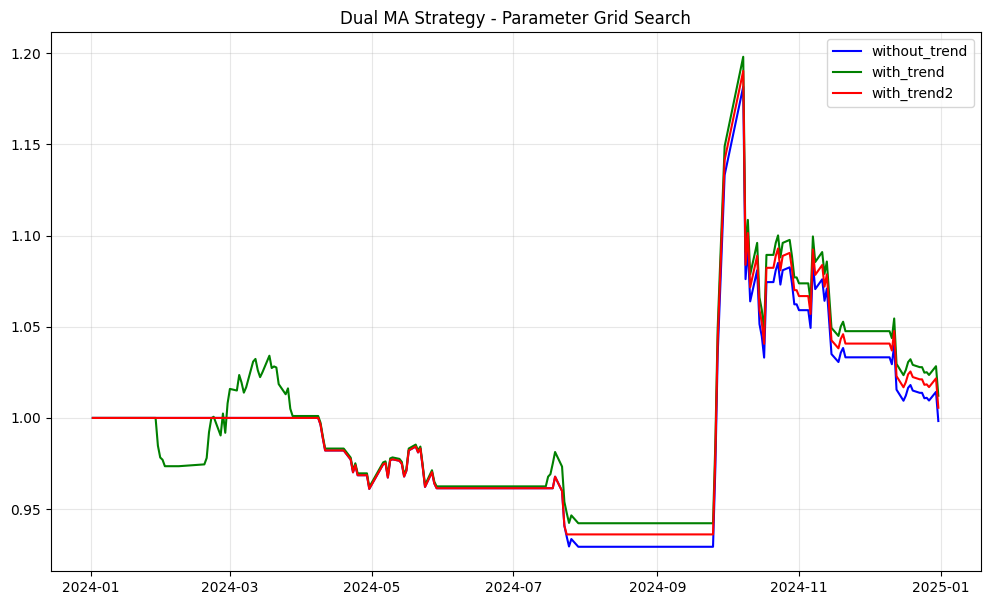

In [15]:
result = {}
result['without_trend']=test_single(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy_with_TrendMA)
result['with_trend']=test_single(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy)
result['with_trend2']=test_single(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy2)
plot_result(result)

In [40]:
def test_single_and_drawdown(symbol="sz000001", 
         start_date="20240101",
         end_date="20241125", 
         Sizers = "percent",
         strategy=DualMAStrategy,
         stake=100,
         origin_cash = 50000,
         plot = False,
         fast = 5,
         slow = 20,
         percent = 95
         ):
    """
    Args:
        symbol: 腾讯源股票代码，如 "sz000001"。
        start_date: 开始日期，格式 YYYYMMDD。
        end_date: 结束日期，格式 YYYYMMDD。
        Sizers: 加仓方式
        strategy: bt.Strategy 子类。
        stake: 每次买入股数，最低 100。
        origin_cash: 起始资金。
        plot: 是否展示k线图
        slow: 策略中的slow参数
        fast: 策略中的fast参数
    Returns:
        None，结果直接打印并绘图。
    """
    print(f"=============== {symbol}: {start_date} --- {end_date} ===============")

    df = ak.stock_zh_a_hist_tx(
        symbol=symbol, start_date=start_date,
        end_date=end_date, adjust="qfq"
    )

    df = df.rename(columns={"amount": "volume"})
    df["date"] = pd.to_datetime(df["date"])
    df.set_index("date", inplace=True)

    data = bt.feeds.PandasData(
        dataname=df[["open", "high", "low", "close", "volume"]]
    )

    cerebro = bt.Cerebro()
    cerebro.broker.setcommission(commission=0.0005)
    cerebro.broker.set_slippage_fixed(fixed=0.01)
    cerebro.adddata(data)
    cerebro.addstrategy(strategy, fast=fast, slow=slow)
    cerebro.broker.setcash(origin_cash)
    
    if Sizers == "fixed":
        cerebro.addsizer(bt.sizers.FixedSize, stake=stake)
    if Sizers == "percent":
        cerebro.addsizer(bt.sizers.PercentSizer, percents = percent)

    cerebro.addanalyzer(bt.analyzers.Returns, _name="returns")
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name="drawdown")
    cerebro.addanalyzer(
        bt.analyzers.SharpeRatio, 
        _name="sharpe",
        timeframe=bt.TimeFrame.Days,  # 告诉它数据是日线
        compression=1,                # 每天的频率
        riskfreerate=0.0,             # 无风险利率设为 0（新手回测通常设为0即可）
        annualize=True,               # 强制开启年化
        factor=252                    # 一年 252 个交易日，让引擎自己换算
    )
    
    # ✅ 新增：添加一个记录每日收益率的分析器
    cerebro.addanalyzer(bt.analyzers.TimeReturn, _name="timereturn")

    print(f"回测前资金: {cerebro.broker.getvalue():.2f}")
    results = cerebro.run()
    strat = results[0]

    final_value = cerebro.broker.getvalue()
    print(f"回测后资金: {final_value:.2f}")

    returns = strat.analyzers.returns.get_analysis()
    drawdown = strat.analyzers.drawdown.get_analysis()
    sharpe = strat.analyzers.sharpe.get_analysis()

    print(f"总收益率: {returns['rtot'] * 100:.2f}%")
    print(f"最大回撤: {drawdown['max']['drawdown']:.2f}%")
    print(f"夏普比率: {sharpe.get('sharperatio', 0)}")
    
    # ✅ 注释掉原来的K线图，我们改用外部画图
    if plot:
        cerebro.plot()  
    
    # ✅ 提取每日收益率，并转换成资金净值曲线
    # TimeReturn 返回的是每日的收益率（如 0.01 代表涨1%）
    time_return = strat.analyzers.timereturn.get_analysis()
    # 将收益率转为 Series，+1 后累乘，算出每天的净值（起点为1）
    nav_series = (pd.Series(time_return) + 1).cumprod()

    cum_max = nav_series.cummax()                      # 历史上的最高净值
    drawdown_series = (nav_series / cum_max) - 1       # 每日的回撤比例
    max_dd_date = drawdown_series.idxmin()             # 回撤最深的那一天
    max_dd_val = drawdown_series.min() * 100           # 回撤的具体数值
    
    print(f"🔥 最大回撤发生日期: {max_dd_date.date()}, 比例: {max_dd_val:.2f}%")
    
    sharpe_val = sharpe.get('sharperatio', 0)
    # ✅ 返回这个净值数据，供主程序画图
    return {
        "nav": nav_series,           # 每日净值曲线
        "returns": returns['rtot'] * 100, # 总收益率
        "sharpe": sharpe_val         # 夏普比率
    }

=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 49915.15
总收益率: -0.17%
最大回撤: 15.51%
夏普比率: 0.08431803672639591
🔥 最大回撤发生日期: 2024-12-31, 比例: -15.51%
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50608.28
总收益率: 1.21%
最大回撤: 15.51%
夏普比率: 0.16116958091479866
🔥 最大回撤发生日期: 2024-12-31, 比例: -15.51%
=============== sh510300: 20240101 --- 20250101 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50279.33
总收益率: 0.56%
最大回撤: 15.51%
夏普比率: 0.1242636582489674
🔥 最大回撤发生日期: 2024-12-31, 比例: -15.51%


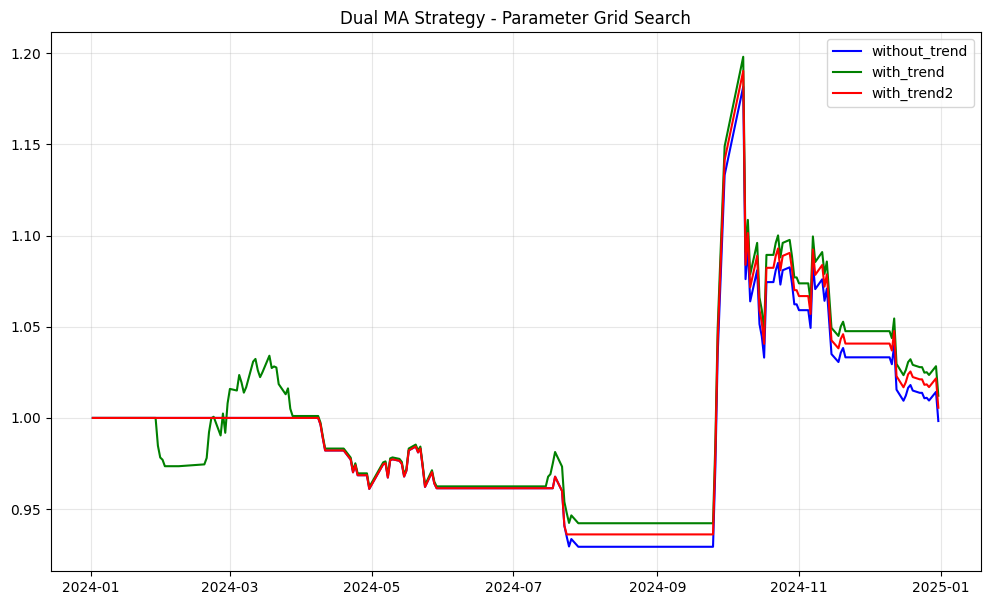

In [22]:
result = {}
result['without_trend']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy_with_TrendMA)
result['with_trend']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy)
result['with_trend2']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250101', fast =5 ,slow = 20, strategy=DualMAStrategy2)
plot_result(result)

In [27]:
class DualMAStrategy_with_StopLoss(bt.Strategy):
    params = (("fast", 5), ("slow", 20), ("stop_loss_pct", 0.05))

    def __init__(self):
        self.fast_ma = bt.indicators.SMA(period=self.p.fast)
        self.slow_ma = bt.indicators.SMA(period=self.p.slow)
        self.trend_ma = bt.indicators.SMA(period=60) 
        self.buy_price = None 
        self.stop_order = None # ✅ 新增：用来记录止损单

    def notify_order(self, order):
        # ✅ 如果止损单被取消或完成，清空记录
        if order.status in [order.Completed, order.Canceled, order.Margin]:
            if order == self.stop_order:
                self.stop_order = None
            if order.status == order.Completed:
                if order.isbuy():
                    self.buy_price = order.executed.price
                elif order.issell():
                    self.buy_price = None

    def next(self):
        if not self.position:
            # 如果有未完成的止损单，先取消
            if self.stop_order is not None:
                self.cancel(self.stop_order)
                
            if self.fast_ma[0] > self.slow_ma[0] and self.data.close[0] > self.trend_ma[0]:
                self.buy()
        else:
            # ✅ 如果持仓了，且还没挂止损单，就在盘中挂一个 Stop 单
            if self.stop_order is None:
                stop_price = self.buy_price * (1 - self.p.stop_loss_pct)
                # 这是一个“跌破 stop_price 就市价卖出”的指令
                self.stop_order = self.sell(exectype=bt.Order.Stop, price=stop_price)
                print(f"挂载止损单！买入价: {self.buy_price:.2f}, 止损线: {stop_price:.2f}")
            
            # 正常死叉卖出逻辑
            if self.fast_ma[0] < self.slow_ma[0]:
                # 如果死叉了，取消止损单，直接市价清仓
                if self.stop_order is not None:
                    self.cancel(self.stop_order)
                self.close()

=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 48356.91
总收益率: -3.34%
最大回撤: 18.15%
夏普比率: -0.08667339868584731
🔥 最大回撤发生日期: 2025-01-03, 比例: -18.15%
=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 49028.40
总收益率: -1.96%
最大回撤: 18.15%
夏普比率: -0.006103289777812033
🔥 最大回撤发生日期: 2025-01-03, 比例: -18.15%
=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
回测后资金: 50104.58
总收益率: 0.21%
最大回撤: 15.81%
夏普比率: 0.10465022213189629
🔥 最大回撤发生日期: 2025-01-02, 比例: -15.81%
=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
挂载止损单！买入价: 3.32, 止损线: 3.16
挂载止损单！买入价: 3.33, 止损线: 3.16
挂载止损单！买入价: 3.41, 止损线: 3.24
挂载止损单！买入价: 3.36, 止损线: 3.20
挂载止损单！买入价: 3.27, 止损线: 3.10
挂载止损单！买入价: 3.94, 止损线: 3.74
挂载止损单！买入价: 3.88, 止损线: 3.68
挂载止损单！买入价: 3.87, 止损线: 3.68
回测后资金: 48132.35
总收益率: -3.81%
最大回撤: 18.53%
夏普比率: -0.10986302942660543
🔥 最大回撤发生日期: 2025-01-02, 比例: -18.53%


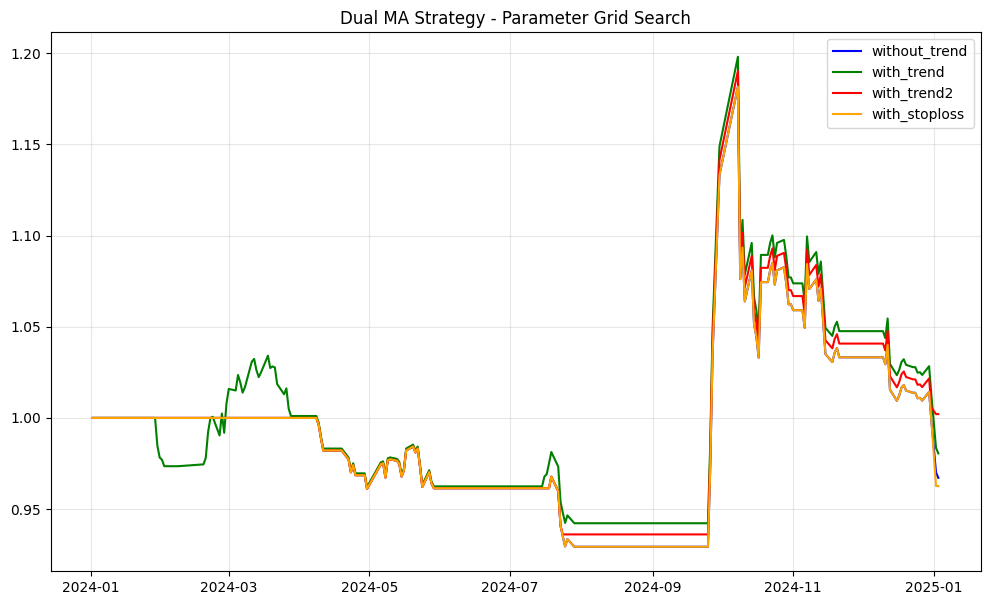

In [29]:
result = {}
result['without_trend']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy_with_TrendMA)
result['with_trend']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy)
result['with_trend2']=test_single_and_drawdown(symbol= "sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy2)
result['with_stoploss'] = test_single_and_drawdown(symbol="sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy_with_StopLoss)
plot_result(result)

In [30]:
result['with_stoploss'] = test_single_and_drawdown(symbol="sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy_with_StopLoss,plot=True)

=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
挂载止损单！买入价: 3.32, 止损线: 3.16
挂载止损单！买入价: 3.33, 止损线: 3.16
挂载止损单！买入价: 3.41, 止损线: 3.24
挂载止损单！买入价: 3.36, 止损线: 3.20
挂载止损单！买入价: 3.27, 止损线: 3.10
挂载止损单！买入价: 3.94, 止损线: 3.74
挂载止损单！买入价: 3.88, 止损线: 3.68
挂载止损单！买入价: 3.87, 止损线: 3.68
回测后资金: 48132.35
总收益率: -3.81%
最大回撤: 18.53%
夏普比率: -0.10986302942660543


<IPython.core.display.Javascript object>

🔥 最大回撤发生日期: 2025-01-02, 比例: -18.53%


In [35]:
class DualMAStrategy3(bt.Strategy):
    # ✅ 修复 1：把 stop_loss_pct 加进参数里
    params = (("fast", 5), ("slow", 20), ("trend", 60), ("stop_loss_pct", 0.05))

    def __init__(self):
        self.fast_ma = bt.indicators.SMA(period=self.p.fast)
        self.slow_ma = bt.indicators.SMA(period=self.p.slow)
        self.trend_ma = bt.indicators.SMA(period=self.p.trend)
        
        # ✅ 修复 2：必须在这里初始化这两个变量，否则 next 里会报错
        self.buy_price = None
        self.stop_order = None

    # ✅ 修复 3：必须加上这个函数，把真实的成交价赋给 self.buy_price
    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin]:
            if order == self.stop_order:
                self.stop_order = None
            if order.status == order.Completed:
                if order.isbuy():
                    self.buy_price = order.executed.price
                elif order.issell():
                    self.buy_price = None

    def next(self):
        if not self.position:
            # 如果有未完成的止损单，先取消
            if self.stop_order is not None:
                self.cancel(self.stop_order)
                self.stop_order = None # 取消后记得置空
                
            # 买入条件：金叉 + 价格在60日线上 + 动量向上（20日线拐头）
            if (self.fast_ma[0] > self.slow_ma[0] and 
                self.data.close[0] > self.trend_ma[0] and 
                self.slow_ma[0] > self.slow_ma[-1]):
                self.buy()
        else:
            # 如果持仓了，且还没挂止损单，就在盘中挂一个 Stop 单
            if self.stop_order is None:
                # 防止 buy_price 还没更新时报错
                if self.buy_price is not None:
                    stop_price = self.buy_price * (1 - self.p.stop_loss_pct)
                    self.stop_order = self.sell(exectype=bt.Order.Stop, price=stop_price)
                    print(f"挂载止损单！买入价: {self.buy_price:.2f}, 止损线: {stop_price:.2f}")
            
            # 正常死叉卖出逻辑
            if self.fast_ma[0] < self.slow_ma[0]:
                if self.stop_order is not None:
                    self.cancel(self.stop_order)
                    self.stop_order = None
                self.close()

In [ ]:
result['with_stoploss'] = test_single_and_drawdown(symbol="sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy3,plot=True)

=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
挂载止损单！买入价: 3.32, 止损线: 3.16
挂载止损单！买入价: 3.41, 止损线: 3.24
挂载止损单！买入价: 3.36, 止损线: 3.20
挂载止损单！买入价: 3.27, 止损线: 3.10
挂载止损单！买入价: 3.88, 止损线: 3.69
挂载止损单！买入价: 3.87, 止损线: 3.68
回测后资金: 50444.36
总收益率: 0.88%
最大回撤: 15.80%
夏普比率: 0.14225997069161425


<IPython.core.display.Javascript object>

🔥 最大回撤发生日期: 2025-01-02, 比例: -15.80%


In [41]:
result['with_stoploss'] = test_single_and_drawdown(symbol="sh510300",start_date='20240101',end_date='20250103', fast =5 ,slow = 20, strategy=DualMAStrategy3,plot=True,percent=30)

=============== sh510300: 20240101 --- 20250103 ===============


  0%|          | 0/3 [00:00<?, ?it/s]

回测前资金: 50000.00
挂载止损单！买入价: 3.32, 止损线: 3.16
挂载止损单！买入价: 3.41, 止损线: 3.24
挂载止损单！买入价: 3.36, 止损线: 3.20
挂载止损单！买入价: 3.27, 止损线: 3.10
挂载止损单！买入价: 3.88, 止损线: 3.69
挂载止损单！买入价: 3.87, 止损线: 3.68
回测后资金: 50257.28
总收益率: 0.51%
最大回撤: 5.69%
夏普比率: 0.11402387103503955


<IPython.core.display.Javascript object>

🔥 最大回撤发生日期: 2025-01-02, 比例: -5.69%


In [45]:
import akshare as ak
import pandas as pd

# 1. 定义标的列表
symbols = ['sh510300', 'sh513100', 'sh518880', 'sh512880', 'sh511010']
etf_data = {} # ✅ 用一个空字典来装数据

# 2. 循环下载
for symbol in symbols:
    print(f"正在下载 {symbol} 的数据...")
    try:
        # 建议用历史数据测试，如果要最新的，可以用 20240101 到 20241125
        df = ak.stock_zh_a_hist_tx(
            symbol=symbol, 
            start_date='20260101', 
            end_date='20261125', 
            adjust="qfq"
        )
        
        # 数据清洗
        df = df.rename(columns={"amount": "volume"}) # 统一列名
        df["date"] = pd.to_datetime(df["date"])
        df.set_index("date", inplace=True)
        
        # ✅ 存入字典
        etf_data[symbol] = df
        
        # 打印最新收盘价和 20 日均线
        close = df['close'].iloc[-1]
        ma20 = df['close'].rolling(window=20).mean().iloc[-1]
        print(f"  -> {symbol} 最新收盘价: {close:.3f}, 20日均线: {ma20:.3f}\n")
        
    except Exception as e:
        print(f"下载 {symbol} 失败: {e}")

正在下载 sh510300 的数据...


  0%|          | 0/1 [00:00<?, ?it/s]

  -> sh510300 最新收盘价: 3.970, 20日均线: 4.086

正在下载 sh513100 的数据...


  0%|          | 0/1 [00:00<?, ?it/s]

  -> sh513100 最新收盘价: 2.049, 20日均线: 2.182

正在下载 sh518880 的数据...


  0%|          | 0/1 [00:00<?, ?it/s]

  -> sh518880 最新收盘价: 7.169, 20日均线: 7.929

正在下载 sh512880 的数据...


  0%|          | 0/1 [00:00<?, ?it/s]

  -> sh512880 最新收盘价: 0.955, 20日均线: 0.991

正在下载 sh511010 的数据...


  0%|          | 0/1 [00:00<?, ?it/s]

  -> sh511010 最新收盘价: 141.416, 20日均线: 141.348



In [46]:
if len(etf_data) > 0:
    close_df = pd.DataFrame()
    for symbol, df in etf_data.items():
        close_df[symbol] = df['close']
    returns_df = close_df.pct_change()
    corr_matrix = returns_df.corr()
    print(corr_matrix.round(2))

          sh510300  sh513100  sh518880  sh512880  sh511010
sh510300      1.00      0.61      0.47      0.63      0.01
sh513100      0.61      1.00      0.41      0.33     -0.02
sh518880      0.47      0.41      1.00      0.30      0.12
sh512880      0.63      0.33      0.30      1.00     -0.11
sh511010      0.01     -0.02      0.12     -0.11      1.00


In [47]:
class MultiAssetDualMA(bt.Strategy):
    params = (("fast",5), ("slow",20))
    def __init__(self):
        self.inds = {}
        for d in self.datas:
            self.inds[d._name] = {
                'fast': bt.indicators.SMA(d.close, period=self.p.fast),
                'slow': bt.indicators.SMA(d.close, period=self.p.slow)
            }
    def next(self):
        for d in self.datas:
            fast_ma = self.inds[d._name]['fast']
            slow_ma = self.inds[d._name]['slow']
            pos = self.getposition(d)
            if not pos:
                if fast_ma[0] > slow_ma[0]:
                    self.buy(data=d)
            else:
                if fast_ma[0] < slow_ma[0]:
                    self.close(data=d)


In [ ]:
def test_multi(
        cash = 50000,
        percent = 45,
        targets = ['sh510300', 'sh511010']
        ):
    """
    Args：
        cash： 现金
        percent： 仓位
        targets： 目标股票
        
    """
    cerebro = bt.Cerebro()
    cerebro.broker.setcash(cash)
    cerebro.addsizer(bt.sizers.PercentSizer, percents = percent)
    cerebro.broker.setcommission(commission=0.0005)
    cerebro.broker.set_slippage_fixed(fixed=0.01)
    for symbol in targets